# Notebook 8 - Distribution Analysis
Sprint 4 - EDA

A distribution describes how the values of a variable are spread: where they are concentrated, how wide they are and what shape they form. In this notebook I first understand the standard shapes (normal, uniform, symmetric, left-skewed and right-skewed) using simulated data where I know the answer, and then I analyse the distribution of my important numerical features. For every feature I explain the shape, center, spread, skewness and presence of outliers.

**Dataset:** Telco Customer Churn (Kaggle, 7043 rows and 21 columns)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statistics import NormalDist

sns.set_style("whitegrid")

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# working copy for analysis only
df_eda = df.copy()
df_eda["TotalCharges"] = pd.to_numeric(df_eda["TotalCharges"], errors="coerce")

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

rng = np.random.default_rng(42)     # fixed seed so the simulated data is the same every time
print("Ready")

Ready


## 1. Normal Distribution

**Concept:** The normal distribution is the symmetric bell shaped curve. Its mean, median and mode are equal and located at the center. It is described completely by its mean and standard deviation. The empirical rule says that about 68% of values are within 1 standard deviation of the mean, about 95% within 2 and about 99.7% within 3. Its skewness is 0 and its excess kurtosis is 0.

**Example (numerical):** Heights of adult men in a city. Most men are near the average height, and very short or very tall men are rare, with the same number on both sides of the average.

Mean: 169.8
Median: 169.96
Skewness: 0.002
Excess kurtosis: 0.037

Within 1 std: 68.6 %
Within 2 std: 95.3 %
Within 3 std: 99.7 %


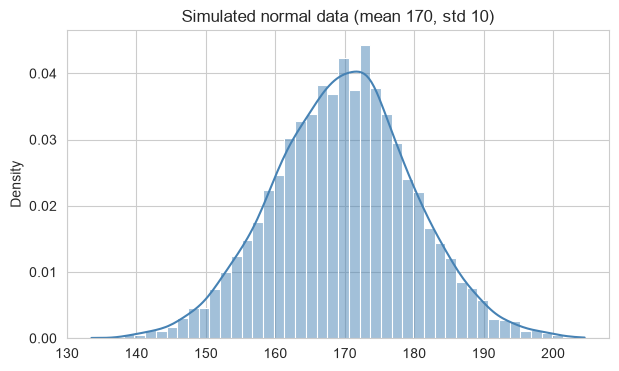

In [2]:
normal_data = pd.Series(rng.normal(loc=170, scale=10, size=5000))

print("Mean:", round(normal_data.mean(), 2))
print("Median:", round(normal_data.median(), 2))
print("Skewness:", round(normal_data.skew(), 3))
print("Excess kurtosis:", round(normal_data.kurt(), 3))
print()

# empirical rule check
for k in [1, 2, 3]:
    share = ((normal_data - normal_data.mean()).abs() <= k * normal_data.std()).mean() * 100
    print("Within", k, "std:", round(share, 1), "%")

plt.figure(figsize=(7, 4))
sns.histplot(normal_data, kde=True, stat="density", color="steelblue")
plt.title("Simulated normal data (mean 170, std 10)")
plt.show()

**What the code does:** It simulates 5000 heights from a normal distribution with mean 170 and standard deviation 10, prints the mean, median, skewness and kurtosis, checks the share of values within 1, 2 and 3 standard deviations, and draws a histogram with a KDE curve.

**Why this method was used:** Simulated data lets me see what a true normal distribution looks like in numbers and in a plot, so I have a reference to compare my real features against.

**What the output means:** The mean and median are almost the same (about 170), the skewness and kurtosis are close to 0, and the shares within 1, 2 and 3 standard deviations are close to 68%, 95% and 99.7%. The histogram is a symmetric bell.

**Insights:** These are the signs of a normal distribution: mean equals median, skewness near 0, kurtosis near 0, and the empirical rule holds. I will use this as a checklist for the real features.

**Effect on the ML pipeline:** Some models assume or work best with normal data, for example linear regression (normal residuals), linear discriminant analysis and Gaussian Naive Bayes. Knowing whether features are normal helps to choose the model or to transform the features.

## 2. Uniform Distribution

**Concept:** In a uniform distribution every value in the range is equally likely, so the histogram is flat like a rectangle. Its skewness is 0 and its excess kurtosis is -1.2, so it is flatter than a normal curve and has no peak.

**Example (business):** The birthday month of customers in a large company is close to uniform, with about one twelfth of the people in each month. A fair die is another example, where each of the 6 faces has a probability of one sixth.

Mean: 49.93 | Median: 50.59
Skewness: -0.007
Excess kurtosis: -1.191


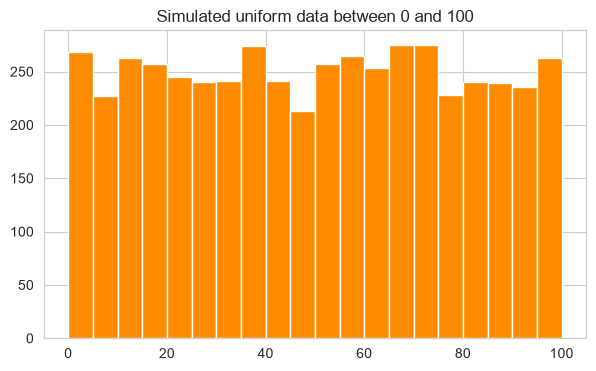

In [3]:
uniform_data = pd.Series(rng.uniform(low=0, high=100, size=5000))

print("Mean:", round(uniform_data.mean(), 2), "| Median:", round(uniform_data.median(), 2))
print("Skewness:", round(uniform_data.skew(), 3))
print("Excess kurtosis:", round(uniform_data.kurt(), 3))

plt.figure(figsize=(7, 4))
plt.hist(uniform_data, bins=20, color="darkorange", edgecolor="white")
plt.title("Simulated uniform data between 0 and 100")
plt.show()

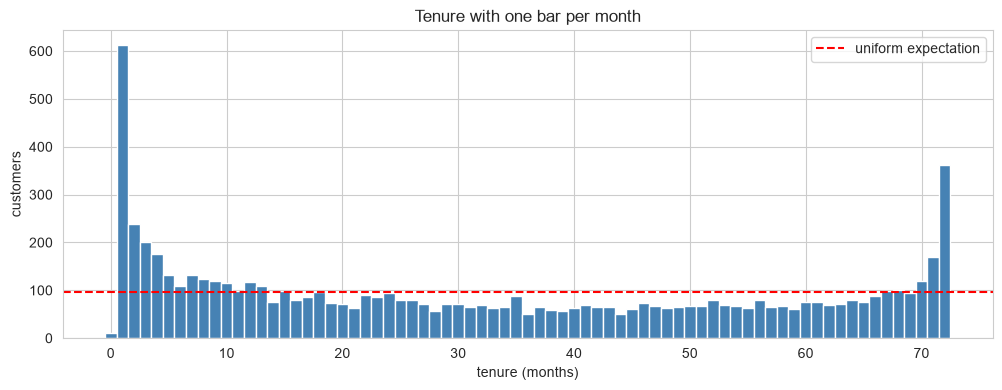

Expected customers per month if uniform: 96.5
Month 1: 613 | Month 72: 362
Average per month for months 2 to 71: 196.0


In [4]:
# is tenure uniform? one bin for every month, and a line for the count a uniform distribution would give
months = np.arange(-0.5, 73.5, 1)
expected = len(df_eda) / 73

plt.figure(figsize=(12, 4))
plt.hist(df_eda["tenure"], bins=months, color="steelblue", edgecolor="white")
plt.axhline(expected, color="red", linestyle="--", label="uniform expectation")
plt.xlabel("tenure (months)")
plt.ylabel("customers")
plt.title("Tenure with one bar per month")
plt.legend()
plt.show()

counts = df_eda["tenure"].value_counts()
print("Expected customers per month if uniform:", round(expected, 1))
print("Month 1:", counts[1], "| Month 72:", counts[72])
print("Average per month for months 2 to 71:", round(counts.loc[2:71].mean(), 1))

**What the code does:** The first cell simulates 5000 values between 0 and 100 and draws their histogram. The second cell draws a histogram of tenure with one bar for each month and a red line at the count that a perfectly uniform tenure would give.

**Why this method was used:** The simulation shows what a uniform shape looks like, and the red line gives a fair way to ask whether tenure is uniform, instead of judging it by eye.

**What the output means:** The simulated histogram is flat, with skewness near 0 and excess kurtosis near -1.2. In the tenure plot most bars from month 2 to month 71 are of similar height, around the red line, but the bars for month 1 and month 72 are much taller than the line.

**Insights:** Tenure is roughly uniform in the middle months, which means customers joined at a fairly steady rate over time. It is not uniform overall, because of the spike of new customers at month 1 and the spike at month 72, which is probably the limit of the data window, as I noted in the outlier notebook.

**Effect on the ML pipeline:** A flat shape means the feature has no strong typical value, so there is nothing to scale around. The spikes at the ends are the part that makes tenure informative, and they are the reason tenure bands may be a useful feature.

## 3. Symmetric, Right-Skewed and Left-Skewed Distributions

**Concept:** In a symmetric distribution the left and the right sides are mirror images, and the mean is about equal to the median. In a right-skewed (positively skewed) distribution the long tail is on the right, so a few large values pull the mean above the median. In a left-skewed (negatively skewed) distribution the long tail is on the left, so a few small values pull the mean below the median. Skewness is the number that measures this. As a rough guide, an absolute value below 0.5 is nearly symmetric, between 0.5 and 1 is moderately skewed and above 1 is highly skewed.

**Example (business):** Household income is right-skewed. Most households earn a moderate amount, but a few very rich households stretch the right tail and pull the mean above the median. This is why reports give the median income and not the mean. The left-skewed case is the mirror image, for example the marks in a very easy exam, where most students score high and a few score very low.

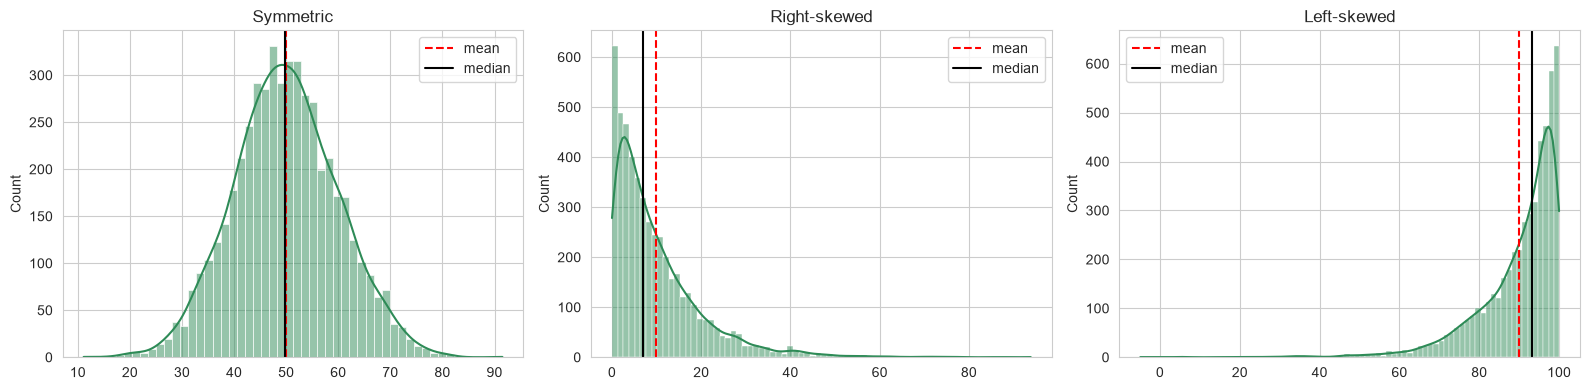

,mean,median,skewness
symmetric,49.95,49.78,0.06
right-skewed,9.93,6.96,2.10
left-skewed,89.97,93.24,-2.22


In [5]:
symmetric = pd.Series(rng.normal(50, 10, 5000))
right_skewed = pd.Series(rng.exponential(scale=10, size=5000))
left_skewed = 100 - pd.Series(rng.exponential(scale=10, size=5000))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, data, name in zip(axes, [symmetric, right_skewed, left_skewed],
                          ["Symmetric", "Right-skewed", "Left-skewed"]):
    sns.histplot(data, kde=True, ax=ax, color="seagreen")
    ax.axvline(data.mean(), color="red", linestyle="--", label="mean")
    ax.axvline(data.median(), color="black", linestyle="-", label="median")
    ax.set_title(name)
    ax.legend()
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    "mean": [symmetric.mean(), right_skewed.mean(), left_skewed.mean()],
    "median": [symmetric.median(), right_skewed.median(), left_skewed.median()],
    "skewness": [symmetric.skew(), right_skewed.skew(), left_skewed.skew()]
}, index=["symmetric", "right-skewed", "left-skewed"])
summary.round(2)

**What the code does:** It simulates one symmetric, one right-skewed and one left-skewed data set, draws a histogram of each with lines for the mean and the median, and prints the mean, median and skewness in a table.

**Why this method was used:** Seeing the three shapes side by side with known data builds the rule I will use on the real features: compare the mean with the median and read the sign of the skewness.

**What the output means:** For the symmetric data the mean and median are almost equal and the skewness is near 0. For the right-skewed data the mean is higher than the median and the skewness is clearly positive (around 2). For the left-skewed data the mean is lower than the median and the skewness is clearly negative (around -2).

**Insights:** The tail points toward the side where the mean is pulled. A positive skew goes with mean greater than median, and a negative skew goes with mean less than median.

**Effect on the ML pipeline:** Skewed features can hurt models that assume symmetric data, and a transformation can fix them. A right skew is commonly reduced with a log or square root, and a left skew with squaring or by reflecting the data first. Tree based models do not need this.

## 4. Skewness and Kurtosis of My Features

**Concept:** Skewness tells the asymmetry. Kurtosis tells the weight of the tails and how peaked the distribution is. In pandas, kurt() gives excess kurtosis, where 0 is like a normal curve. A positive value (leptokurtic) means heavy tails and a sharp peak, and a negative value (platykurtic) means light tails and a flat shape. A negative kurtosis very often means that the data is flat or has more than one peak.

**Example (AI/ML):** Financial returns often have a positive kurtosis, because large gains and losses happen more often than a normal curve predicts. A model that assumes normality will underestimate the risk of extreme events.

In [6]:
def skew_label(s):
    if abs(s) < 0.5:
        return "nearly symmetric"
    if abs(s) < 1:
        return "moderately skewed"
    return "highly skewed"

def kurt_label(k):
    if k > 0.5:
        return "heavy tails (leptokurtic)"
    if k < -0.5:
        return "light tails or flat (platykurtic)"
    return "close to normal (mesokurtic)"

rows = []
for col in num_cols:
    s = df_eda[col].skew()
    k = df_eda[col].kurt()
    direction = "right" if s > 0 else "left"
    rows.append([col, round(s, 2), skew_label(s) + " (" + direction + ")", round(k, 2), kurt_label(k)])

pd.DataFrame(rows, columns=["feature", "skewness", "skew meaning", "excess kurtosis", "kurtosis meaning"])

,feature,skewness,skew meaning,excess kurtosis,kurtosis meaning
0,tenure,0.24,nearly symmetric (right),-1.39,light tails or flat (platykurtic)
1,MonthlyCharges,-0.22,nearly symmetric (left),-1.26,light tails or flat (platykurtic)
2,TotalCharges,0.96,moderately skewed (right),-0.23,close to normal (mesokurtic)


**What the code does:** It defines two small functions that turn the skewness and kurtosis numbers into words with the rough thresholds, and then applies them to the three numerical features.

**Why this method was used:** Turning numbers into labels with fixed thresholds makes the comparison consistent for every feature, and the thresholds are only rules of thumb.

**What the output means:** Tenure has a skewness of about 0.24 (nearly symmetric) and a kurtosis of about -1.4 (flat). MonthlyCharges has a skewness of about -0.22 (nearly symmetric) and a kurtosis of about -1.3 (flat). TotalCharges has a skewness of about 0.96 (moderately skewed to the right, close to the highly skewed limit) and a kurtosis of about -0.2 (close to normal).

**Insights:** Tenure and MonthlyCharges have a low skewness but this does not mean they are normal, because their kurtosis is very negative, which comes from having more than one peak. Skewness alone can be misleading. TotalCharges is the only clearly skewed feature.

**Effect on the ML pipeline:** Both numbers are needed to judge a distribution. A feature with low skewness and strong negative kurtosis, like tenure, will not be fixed by a log transformation, and might be better handled by binning.

## 5. Distribution Analysis of the Important Numerical Features

**Concept:** To describe a distribution fully I answer five questions: What is the shape? Where is the center? How wide is the spread? Is it skewed? Are there outliers? Two helpful tools are a histogram with a normal curve of the same mean and standard deviation drawn over it, and a Q-Q plot. A Q-Q plot compares the sorted data with the values expected from a normal distribution, and if the data is normal, the points fall on the straight red line.

**Example (AI/ML):** Before using linear regression, an analyst draws a Q-Q plot of the residuals. If the points curve away from the line at the ends, the residuals have heavier tails than a normal curve, and the confidence intervals of the model cannot be trusted.

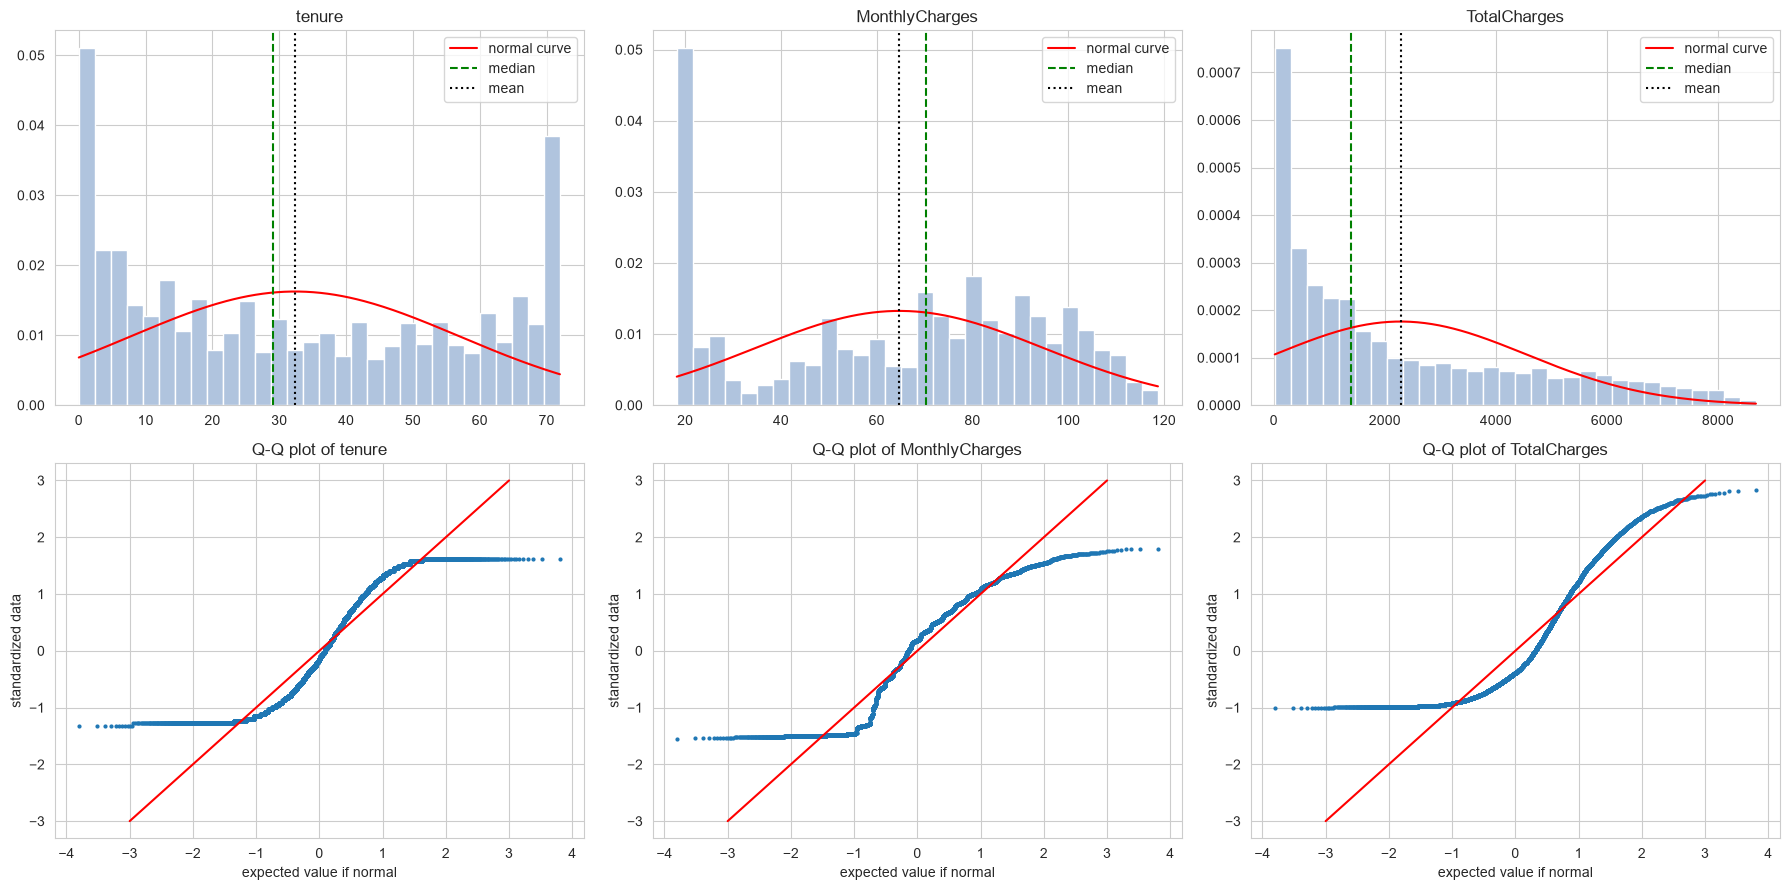

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))

for i, col in enumerate(num_cols):
    data = df_eda[col].dropna()
    m, s = data.mean(), data.std()

    # histogram with normal curve of the same mean and std
    ax = axes[0, i]
    ax.hist(data, bins=30, density=True, color="lightsteelblue", edgecolor="white")
    x = np.linspace(data.min(), data.max(), 200)
    ax.plot(x, np.exp(-0.5 * ((x - m) / s) ** 2) / (s * np.sqrt(2 * np.pi)), color="red", label="normal curve")
    ax.axvline(data.median(), color="green", linestyle="--", label="median")
    ax.axvline(m, color="black", linestyle=":", label="mean")
    ax.set_title(col)
    ax.legend()

    # Q-Q plot
    ax = axes[1, i]
    sorted_data = np.sort(data.values)
    probs = (np.arange(1, len(sorted_data) + 1) - 0.5) / len(sorted_data)
    theoretical = np.array([NormalDist().inv_cdf(p) for p in probs])
    ax.scatter(theoretical, (sorted_data - m) / s, s=4)
    ax.plot([-3, 3], [-3, 3], color="red")
    ax.set_xlabel("expected value if normal")
    ax.set_ylabel("standardized data")
    ax.set_title("Q-Q plot of " + col)

plt.tight_layout()
plt.show()

**What the code does:** The top row draws a histogram of each feature with a red normal curve of the same mean and standard deviation, and lines for the mean and median. The bottom row draws a Q-Q plot of each feature against the normal distribution. The expected normal values are calculated with the inverse normal function from the Python statistics module.

**Why this method was used:** The red curve shows how far the real shape is from a normal bell, and the Q-Q plot shows where it differs (the center or the tails). I used the standard library function so that no extra package is needed.

**What the output means:** None of the three histograms follows the red curve well. In the Q-Q plots tenure and MonthlyCharges follow an S shaped pattern that crosses the line, which is typical of flat or multi-peaked data. TotalCharges curves strongly upward at the right end and is above the line, which is the pattern of a right-skewed distribution.

**Insights:** All three features differ from the normal distribution, each in its own way: tenure and MonthlyCharges because they are flat and multimodal, and TotalCharges because of its right tail.

**Effect on the ML pipeline:** Models that assume normality should not be applied to these features without care. The data is not suitable for tests based on normality, and the features may need binning or transformations.

In [8]:
rows = []
for col in num_cols:
    data = df_eda[col].dropna()
    m, s = data.mean(), data.std()
    q1, q3 = data.quantile(0.25), data.quantile(0.75)
    iqr = q3 - q1
    n_out = ((data < q1 - 1.5 * iqr) | (data > q3 + 1.5 * iqr)).sum()
    rows.append([col,
                 round(m, 1), round(data.median(), 1),
                 round(s, 1), round(iqr, 1),
                 round(data.skew(), 2), round(data.kurt(), 2),
                 round(((data - m).abs() <= s).mean() * 100, 1),
                 round(((data - m).abs() <= 2 * s).mean() * 100, 1),
                 n_out])

profile = pd.DataFrame(rows, columns=["feature", "mean", "median", "std", "IQR", "skew", "kurtosis",
                                       "within_1_std_%", "within_2_std_%", "outliers_IQR"])
profile

,feature,mean,median,std,IQR,skew,kurtosis,within_1_std_%,within_2_std_%,outliers_IQR
0,tenure,32.4,29.0,24.6,46.0,0.24,-1.39,53.3,100.0,0
1,MonthlyCharges,64.8,70.4,30.1,54.4,-0.22,-1.26,56.8,100.0,0
2,TotalCharges,2283.3,1397.5,2266.8,3393.3,0.96,-0.23,80.7,94.4,0


**What the code does:** It builds a profile table with the center (mean and median), the spread (standard deviation and IQR), the skewness, the kurtosis, the share of values within 1 and 2 standard deviations, and the number of IQR outliers for each feature.

**Why this method was used:** Putting all the measures in one table makes it easy to answer the five questions for every feature, and the empirical rule shares show directly how far each feature is from a normal bell (68% and 95% would be normal).

**What the output means:** The shares within 1 and 2 standard deviations differ from 68% and 95% in different ways for each feature, and the number of IQR outliers is 0 for all three, as found in the outlier notebook. The mean is close to the median for tenure and MonthlyCharges, and clearly above the median for TotalCharges.

**Insights:** The numbers confirm what the plots showed: the empirical rule does not hold, so the features are not normal. Having no outliers while having skew shows once more that skew and outliers are different problems.

**Effect on the ML pipeline:** The profile table can be used as a baseline to compare the features before and after scaling or transformation in the preprocessing sprint.

### Reading each feature

**tenure**
- Shape: flat in the middle with two tall bars at the ends (month 1 and month 72), which is a U shape. It is not a bell.
- Center: mean about 32 and median 29, so they are close but not the same, and the center is not very meaningful for a U shaped variable.
- Spread: wide, standard deviation about 25 on a range of 0 to 72, and an IQR of about 46.
- Skewness: about 0.24, which is nearly symmetric, and kurtosis about -1.4, which is very flat.
- Outliers: none.

**MonthlyCharges**
- Shape: multimodal, with a big peak near 20 (customers without internet) and a broad group between about 70 and 100.
- Center: mean about 65 and median about 70, which are close, but few customers are actually near the mean.
- Spread: wide, standard deviation about 30 on a range of about 18 to 119.
- Skewness: about -0.22, which is nearly symmetric, and kurtosis about -1.3, which is flat.
- Outliers: none.

**TotalCharges**
- Shape: one peak at the low end with a long tail to the right, like an exponential shape.
- Center: mean about 2283 is far above the median of about 1397, which is the sign of right skew.
- Spread: very wide, standard deviation about 2267, close to the mean.
- Skewness: about 0.96, which is moderately to highly right-skewed, and kurtosis about -0.2.
- Outliers: none by the IQR rule, because the tail is smooth.

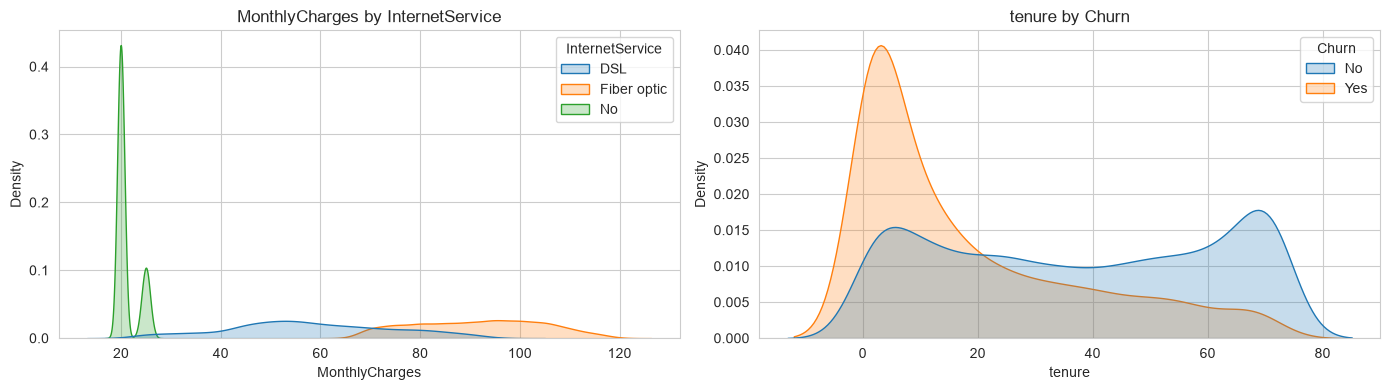

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# MonthlyCharges looks like a mixture of groups
sns.kdeplot(data=df_eda, x="MonthlyCharges", hue="InternetService", fill=True, common_norm=False, ax=axes[0])
axes[0].set_title("MonthlyCharges by InternetService")

# tenure by churn
sns.kdeplot(data=df_eda, x="tenure", hue="Churn", fill=True, common_norm=False, ax=axes[1])
axes[1].set_title("tenure by Churn")

plt.tight_layout()
plt.show()

**What the code does:** It draws one KDE curve for each internet service type for MonthlyCharges, and one for each Churn class for tenure. common_norm=False makes each curve use its own area, so groups of different sizes can be compared.

**Why this method was used:** The earlier plots showed that tenure and MonthlyCharges have more than one peak. Splitting by a categorical feature tests whether the peaks come from different groups of customers.

**What the output means:** In MonthlyCharges the no internet group is a narrow peak at the low end, the DSL group is in the middle and the fiber optic group is at the high end. For tenure, the churned group is concentrated at the low end, and the not churned group has a peak at the low end and a bigger peak at the high end.

**Insights:** The multimodal shape of MonthlyCharges is a mix of three separate distributions, one for each service type, and each of them is closer to a single bell on its own. The two peaks of tenure come from the stay-or-leave behavior, because churners leave early and the loyal customers stay to the end.

**Effect on the ML pipeline:** A single overall distribution hides group differences, so features such as InternetService should be kept alongside MonthlyCharges. For a model, these groups can be learned from the categorical features, and interaction features could help linear models.

# Findings

| Feature | Shape | Center | Spread | Skewness | Outliers | Normal? |
|---|---|---|---|---|---|---|
| tenure | U shaped, flat in the middle, spikes at 1 and 72 | mean 32, median 29 | wide, std about 25 | about 0.24 (nearly symmetric), very flat | none | No |
| MonthlyCharges | multimodal, peak near 20 and a broad group near 70 to 100 | mean 65, median 70 | wide, std about 30 | about -0.22 (nearly symmetric), flat | none | No |
| TotalCharges | single peak at the low end, long right tail | mean 2283, median 1397 | very wide, std about 2267 | about 0.96 (right-skewed) | none | No |

# Summary

- None of the three numerical features is normally distributed.
- Tenure and MonthlyCharges are flat or multimodal, so their low skewness is not a sign of normality, and the kurtosis shows it.
- TotalCharges is the only clearly right-skewed feature, and it is also the one that a transformation can improve.
- The multimodal shapes come from groups of customers (internet service type, and churn behavior).
- Skewness, outliers and normality are three different things, and each needs a separate check.

**Points for later sprints**
1. Consider a square root or log transformation of TotalCharges for models that are sensitive to skew.
2. Consider binning tenure (for example 0 to 12, 13 to 24, 25 to 48 and 49 to 72 months).
3. Use scaling for distance based and gradient based models because the ranges are very different.
4. Do not use methods that assume normality on the raw features.
5. Keep InternetService with MonthlyCharges, because the MonthlyCharges shape is a mixture of groups.

**What I learned:** A low skewness does not mean a distribution is normal, so I must also check the kurtosis and look at the plot. A Q-Q plot shows how a feature differs from a normal curve, and a multimodal shape often means that different groups are mixed together.

Next: `09_Categorical_Analysis.ipynb`